In [54]:
# Import the pandas library for data analysis
import pandas as pd

# Load data files processed and cleaned by teammate
ba_jobs = pd.read_csv("ba_jobs_clean.csv")
location_counts = pd.read_csv("job_location_counts.csv")


In [55]:
# Display the first five rows to confirm that the file was imported correctly
ba_jobs.head()


,job_link,last_processed_time,got_summary,got_ner,is_being_worked,job_title,company,job_location,first_seen,search_city,search_country,search_position,job_level,job_type,job_skills_raw,skills_normalized_json,skill_count
0,https://au.linkedin.com/jobs/view/agile-busine...,2024-01-19 09:45:09.215838+00,t,t,f,Agile Business Analyst,MYP Corporation,"Brisbane, Queensland, Australia",2024-01-13,Deception Bay,Australia,Consultant Education,Mid senior,Onsite,"Agile methodologies, Business Analysis, Requir...","[""agile methodologies"", ""analytical skills"", ""...",23
1,https://au.linkedin.com/jobs/view/agile-busine...,2024-01-19 09:45:09.215838+00,t,t,f,Agile Business Analyst,MYP Corporation,"Brisbane, Queensland, Australia",2024-01-13,Deception Bay,Australia,Consultant Education,Mid senior,Onsite,"Agile methodologies, Business analysis, User s...","[""agile methodologies"", ""analytical skills"", ""...",20
2,https://au.linkedin.com/jobs/view/agile-busine...,2024-01-19 21:14:01.911673+00,t,t,f,Agile Business Analyst / Scrum Master,Araza,"Melbourne, Victoria, Australia",2024-01-13,Victoria,Australia,Quality Assurance Analyst,Mid senior,Onsite,"Agile, Scrum Master, Business Analysis, User S...","[""advanced excel"", ""agile"", ""agile scrum metho...",22
3,https://au.linkedin.com/jobs/view/bi-business-...,2024-01-19 09:45:09.215838+00,t,t,f,BI Business Analyst,Metcash,"Macquarie Park, New South Wales, Australia",2024-01-13,New South Wales,Australia,Data Communications Analyst,Mid senior,Onsite,"Business Analysis, BI & Analytics, Data Wareho...","[""analytics"", ""bi & analytics"", ""business anal...",13
4,https://au.linkedin.com/jobs/view/business-ana...,2024-01-19 09:45:09.215838+00,t,t,f,Business Analyst – Commodities,Luxoft,"Sydney, New South Wales, Australia",2024-01-13,New South Wales,Australia,Management Analyst,Mid senior,Onsite,"Business Analysis, Capital Markets, Commoditie...","[""brd"", ""business analysis"", ""business analyst...",17


In [56]:
location_counts.head()

,job_location,postings
0,"New York, NY",50
1,"London, England, United Kingdom",42
2,"Atlanta, GA",41
3,"Boston, MA",38
4,"Richmond, VA",34


In [57]:
# Check the dimensions of the dataframe: (number of rows, number of columns)

location_counts.shape

(626, 2)

# Data Quality Assessment

a. Assessing location_counts DataFrame

In [58]:
# Display column names and data types

location_counts.info()

<class 'pandas.DataFrame'>
RangeIndex: 626 entries, 0 to 625
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   job_location  626 non-null    str  
 1   postings      626 non-null    int64
dtypes: int64(1), str(1)
memory usage: 21.3 KB


In [59]:
# Check for missing values in each column

location_counts.isnull().sum()

job_location    0
postings        0
dtype: int64

In [60]:
# Check whether any location labels appear more than once

location_counts.duplicated(subset="job_location").sum()

np.int64(0)

In [61]:
'''Verify that the total posting count in the location summary file matches
    the total number of records used in the project dataset.'''

location_counts["postings"].sum()

np.int64(1929)

b. Assessing ba_jobs DataFrame

In [62]:
# Display the number of rows and columns in the dataset.

ba_jobs.shape

(1929, 17)

In [63]:
# Review column names, data types, and non-null counts.

ba_jobs.info()

<class 'pandas.DataFrame'>
RangeIndex: 1929 entries, 0 to 1928
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   job_link                1929 non-null   str  
 1   last_processed_time     1929 non-null   str  
 2   got_summary             1929 non-null   str  
 3   got_ner                 1929 non-null   str  
 4   is_being_worked         1929 non-null   str  
 5   job_title               1929 non-null   str  
 6   company                 1929 non-null   str  
 7   job_location            1929 non-null   str  
 8   first_seen              1929 non-null   str  
 9   search_city             1929 non-null   str  
 10  search_country          1929 non-null   str  
 11  search_position         1929 non-null   str  
 12  job_level               1929 non-null   str  
 13  job_type                1929 non-null   str  
 14  job_skills_raw          1929 non-null   str  
 15  skills_normalized_json  1929 non

In [64]:
# Check for missing values in each column.

ba_jobs.isnull().sum()

job_link                  0
last_processed_time       0
got_summary               0
got_ner                   0
is_being_worked           0
job_title                 0
company                   0
job_location              0
first_seen                0
search_city               0
search_country            0
search_position           0
job_level                 0
job_type                  0
job_skills_raw            0
skills_normalized_json    0
skill_count               0
dtype: int64

In [65]:
# Check for duplicate job links.

ba_jobs["job_link"].duplicated().sum()

np.int64(0)

In [66]:
# Review the distribution of postings across countries.
 
ba_jobs["search_country"].value_counts()

search_country
United States     1480
United Kingdom     196
Canada             137
Australia          116
Name: count, dtype: int64

In [67]:
# Verify the total number of records in the cleaned dataset.

len(ba_jobs)

1929

# 4.3.1. Regional aggregation counts

# Exploration of Job Location Distribution

In [68]:
# Overview of the distribution of job postings across locations.

location_counts["postings"].describe()

count    626.00000
mean       3.08147
std        5.28558
min        1.00000
25%        1.00000
50%        1.00000
75%        2.00000
max       50.00000
Name: postings, dtype: float64

# Examine Location Formats

In [69]:
'''Display a random sample of location labels to identify differences 
    in formatting that may affect the regional aggregation process.'''
 
location_counts.sample(
30,
random_state=42
)

,job_location,postings
448,"Tacoma, WA",1
486,"Centennial, CO",1
215,"Purchase, NY",2
212,"Burlington, VT",2
481,"Winston-Salem, NC",1
503,"Santa Barbara, CA",1
163,"Harrow, England, United Kingdom",2
77,"Fort Lauderdale, FL",5
528,"Shanghai, VA",1
145,"Georgia, United States",3


In [70]:
location_counts.sort_values(by="postings",ascending=False).head(20)

,job_location,postings
0,"New York, NY",50
1,"London, England, United Kingdom",42
2,"Atlanta, GA",41
3,"Boston, MA",38
4,"Richmond, VA",34
5,"Montreal, Quebec, Canada",28
6,"Tallahassee, FL",27
7,"Austin, TX",27
8,"Chicago, IL",26
9,"Dallas, TX",24


In [71]:
# Sort all locations by posting count in descending order

locations_sorted = location_counts.sort_values(by="postings",ascending=False)

# Export the sorted table to a CSV file

locations_sorted.to_csv("locations_sorted.csv",index=False)

In [72]:
locations_sorted

,job_location,postings
0,"New York, NY",50
1,"London, England, United Kingdom",42
2,"Atlanta, GA",41
3,"Boston, MA",38
4,"Richmond, VA",34
...,...,...
621,"Cranberry Township, PA",1
622,"San Jose, CA",1
623,"Riverside County, CA",1
624,"Florida, United States",1


# Create Regional Groups

In [73]:
# Classify each location into a market group based on keywords appearing in the location label.

def classify_market(location):

    location = str(location)

    international_keywords = [
        "United Kingdom",
        "England",
        "Canada",
        "Australia",
        "Victoria, Australia",
        "New South Wales",
        "Queensland",
        "Ontario",
        "British Columbia",
        "Alberta"
    ]

    for keyword in international_keywords:
        if keyword in location:
            return "International Markets"

    return "United States"

In [74]:
# Apply the classification function to create a new market group column.

location_counts["market_group"] = (location_counts["job_location"].apply(classify_market))

location_counts.head()


,job_location,postings,market_group
0,"New York, NY",50,United States
1,"London, England, United Kingdom",42,International Markets
2,"Atlanta, GA",41,United States
3,"Boston, MA",38,United States
4,"Richmond, VA",34,United States


In [75]:
location_counts.to_csv("locations_counts.csv",index=False)

In [76]:
ba_jobs["search_country"].value_counts()

search_country
United States     1480
United Kingdom     196
Canada             137
Australia          116
Name: count, dtype: int64

In [77]:
location_check = ba_jobs[["job_location", "search_country"]]

In [78]:
location_check.to_csv("location_check.csv",index=False)

# Change in Approach
The initial location classification produced several incorrect groupings due to inconsistent location formats. To improve accuracy, the analysis was continued using the search_country field from the ba_jobs_clean dataset.

In [79]:
# Count the number of postings in each country.

country_counts = (ba_jobs["search_country"].value_counts().reset_index())

country_counts.columns = ["Country","Postings"]

country_counts

,Country,Postings
0,United States,1480
1,United Kingdom,196
2,Canada,137
3,Australia,116


In [80]:
# Create Market Groups using ba_jobs_clean dataset.

ba_working = ba_jobs.copy()

ba_working["market_group"] = ba_working["search_country"].apply(lambda x: "United States" if x == "United States" else "International Markets")

# Review the new grouping variable.

ba_working[["search_country", "market_group"]].head()

ba_working.to_csv("marketgroup_check.csv",index=False)



In [81]:
# Calculate posting counts by market group.

market_counts = (ba_working["market_group"].value_counts().reset_index())

market_counts.columns = ["Market Group","Postings"]

market_counts

,Market Group,Postings
0,United States,1480
1,International Markets,449


In [82]:
# Calculate the percentage share of postings in each market group.

market_counts["Percentage"] = (market_counts["Postings"] / market_counts["Postings"].sum() * 100).round(2)

market_counts

,Market Group,Postings,Percentage
0,United States,1480,76.72
1,International Markets,449,23.28


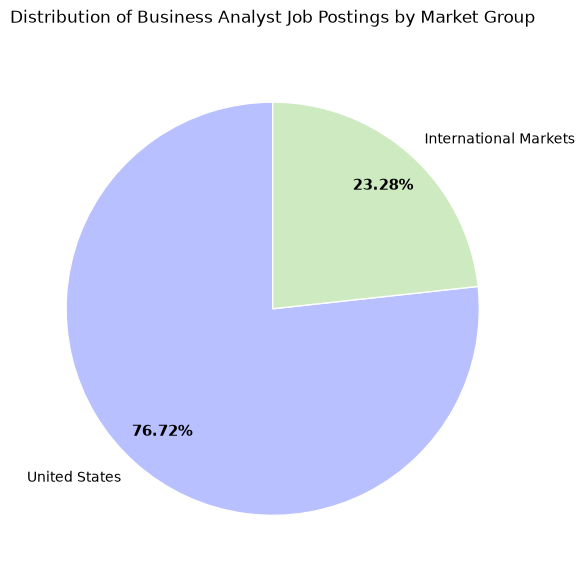

In [84]:
import matplotlib.pyplot as plt

# Create a donut chart showing the proportion of postings
# in each market group.

plt.figure(figsize=(6, 6))

colors = ["#B8C0FF", "#CDEAC0"]

patches, texts, autotexts = plt.pie(
    market_counts["Postings"],
    labels=market_counts["Market Group"],
    autopct="%1.2f%%",
    pctdistance=0.8,  # move percentages outward
    colors=colors,
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

# Format percentage labels

for autotext in autotexts:
    autotext.set_color("black")
    autotext.set_fontsize(11)
    autotext.set_fontweight("bold")


plt.title("Distribution of Business Analyst Job Postings by Market Group",pad=20)

plt.tight_layout()

plt.savefig("Market_Group_Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

# 4.3.2 Two Sample Proportion Z Test

In [85]:
import json

''' Convert the JSON text stored in the skills column into Python lists to search and count individual skills '''
 
ba_working["skills_list"] = (ba_working["skills_normalized_json"].apply(json.loads))
 
# Review a sample of converted skill lists.
 
ba_working[["job_title", "skills_list"]].head()

,job_title,skills_list
0,Agile Business Analyst,"[agile methodologies, analytical skills, atten..."
1,Agile Business Analyst,"[agile methodologies, analytical skills, busin..."
2,Agile Business Analyst / Scrum Master,"[advanced excel, agile, agile scrum methodolog..."
3,BI Business Analyst,"[analytics, bi & analytics, business analysis,..."
4,Business Analyst – Commodities,"[brd, business analysis, business analyst cert..."


# Review of Skill Labels

In [86]:
# Combine all skills into a single column.

skill_series = (ba_working["skills_list"].explode())

# Count the frequency of each skill.

skill_counts = (skill_series.value_counts().reset_index())

skill_counts.columns = ["Skill","Frequency"]

# Display the 50 most frequent skills.

skill_counts.head(50)

,Skill,Frequency
0,business analysis,1929
1,communication,1050
2,project management,818
3,problem solving,650
4,data analysis,620
5,requirements gathering,494
6,sql,419
7,analytical skills,343
8,stakeholder management,310
9,agile,282


In [89]:
skill_counts.to_csv("skill_counts.csv",index=False)

In [90]:
# Create binary indicators for SQL, Excel, and Tableau.
 
ba_working["sql"] = (ba_working["skills_list"].apply(lambda skills: "sql" in skills))
 
ba_working["excel"] = (ba_working["skills_list"].apply(lambda skills: "excel" in skills))
 
ba_working["tableau"] = (ba_working["skills_list"].apply(lambda skills: "tableau" in skills))

ba_working["python"] = (ba_working["skills_list"].apply(lambda skills: "python" in skills))

In [91]:
# Count the number of postings that contain each tool.

print("SQL:", ba_working["sql"].sum())
print("Excel:", ba_working["excel"].sum())
print("Tableau:", ba_working["tableau"].sum())
print("Python:", ba_working["python"].sum())

SQL: 419
Excel: 275
Tableau: 150
Python: 115


# Compare Analytical Tool Demand Across Market Groups

In [93]:
tool_demand = (ba_working.groupby("market_group").agg(SQL=("sql", "mean"),Excel=("excel", "mean"),
                                                Tableau=("tableau", "mean"),Python=("python", "mean"))* 100)

tool_demand = (tool_demand.round(2).reset_index())

tool_demand

,market_group,SQL,Excel,Tableau,Python
0,International Markets,15.14,11.8,6.90,5.57
1,United States,23.72,15.0,8.04,6.08


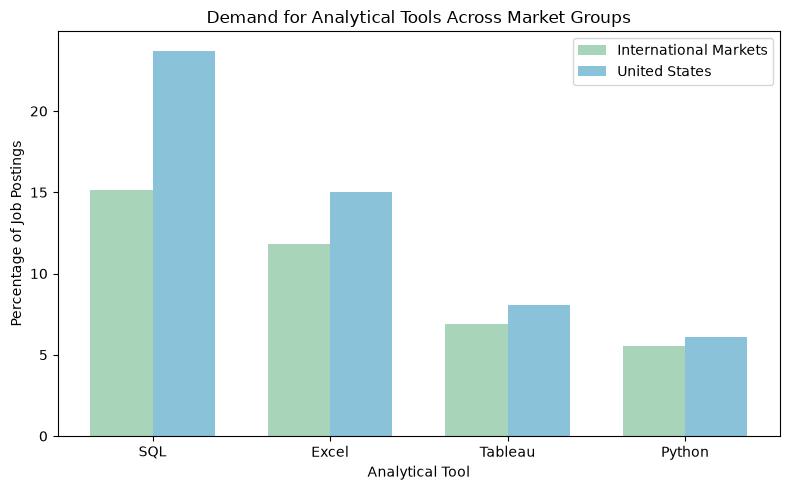

In [94]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting

tools = ["SQL", "Excel", "Tableau", "Python"]

international = tool_demand.iloc[0, 1:]
united_states = tool_demand.iloc[1, 1:]

x = np.arange(len(tools))
width = 0.35

# Create grouped bar chart

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, international, width, label="International Markets", color="#A8D5BA")

plt.bar(x + width/2, united_states, width, label="United States", color="#89C2D9")

plt.xticks(x, tools)

plt.ylabel("Percentage of Job Postings")
plt.xlabel("Analytical Tool")

plt.title("Demand for Analytical Tools Across Market Groups")

plt.legend()

plt.tight_layout()

# Export figure

plt.savefig("Analytical_Tool_Demand.png",dpi=300,bbox_inches="tight")

plt.show()

# Run z-tests

In [95]:
from statsmodels.stats.proportion import proportions_ztest

# List of tools to test

tools = ["sql", "excel", "tableau", "python"]

results = []

for tool in tools:
    us_count = (ba_working[ba_working["market_group"] == "United States"][tool].sum())

    int_count = (ba_working[ba_working["market_group"] == "International Markets"][tool].sum())

    count = [us_count, int_count]

    nobs = [1480, 449]

    z_stat, p_value = proportions_ztest(count,nobs)

    results.append([tool.title(), us_count, int_count, round(z_stat, 4), round(p_value, 6)])



In [96]:
# Create results table

ztest_results = pd.DataFrame(results, columns=["Tool","US Count","International Count","Z Statistic","P Value"])

ztest_results.to_csv("ztest_results.csv",index=False)

ztest_results

,Tool,US Count,International Count,Z Statistic,P Value
0,Sql,351,68,3.8581,0.000114
1,Excel,222,53,1.6966,0.089763
2,Tableau,119,31,0.7876,0.430955
3,Python,90,25,0.4023,0.687498


In [99]:
# Create a results table for report

aq3_results = pd.DataFrame({
    "Tool": ["SQL", "Excel", "Tableau", "Python"],
    "United States (%)": [23.72, 15.00, 8.04, 6.08],
    "International Markets (%)": [15.14, 11.80, 6.90, 5.57],
    "Z Statistic": [3.8581, 1.6966, 0.7876, 0.4023],
    "P Value": [0.000114, 0.089763, 0.430955, 0.687498]
})

aq3_results["Significant"] = (aq3_results["P Value"].apply(lambda x: "Yes" if x < 0.05 else "No"))

aq3_results.to_csv("aq3_results.csv",index=False)
aq3_results

,Tool,United States (%),International Markets (%),Z Statistic,P Value,Significant
0,SQL,23.72,15.14,3.8581,0.000114,Yes
1,Excel,15.00,11.80,1.6966,0.089763,No
2,Tableau,8.04,6.90,0.7876,0.430955,No
3,Python,6.08,5.57,0.4023,0.687498,No
